import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


In [6]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles available:")
print(os.listdir())

Current working directory:
C:\Users\varsh\Indian_Business_EDA

Files available:
['.git', '.ipynb_checkpoints', 'indian_business.db', 'W1D1_SQL_Fundamentals.ipynb', 'W1D2_SQL_Joins.ipynb.ipynb', 'W1D3_SQL_GroupBy_Having.ipynb.ipynb', 'W1D4_SQL_Subqueries.ipynb.ipynb', 'W1D5_SQL_Case_When.ipynb.ipynb', 'W2D1_Data_Visualisation.ipynb.ipynb']


In [8]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("indian_business.db")

print("Database connected successfully!")

Database connected successfully!


In [10]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Available tables:")
print(tables)

Available tables:
         name
0  businesses
1      owners


In [12]:
table_name = tables.iloc[0]["name"]

df = pd.read_sql_query(
    f'SELECT * FROM "{table_name}"',
    conn
)

print("Business dataset loaded successfully!")
df.head()

Business dataset loaded successfully!


,Business_ID,Business_Name,City
0,101,FreshMart,Bangalore
1,102,TechZone,Mumbai
2,103,GreenLeaf,Chennai
3,104,Cafe Aroma,Bangalore
4,105,StyleHub,Hyderabad


In [14]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5
Number of columns: 3


In [16]:
print("Dataset Columns:")
print(df.columns.tolist())

Dataset Columns:
['Business_ID', 'Business_Name', 'City']


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Business_ID    5 non-null      int64
 1   Business_Name  5 non-null      str  
 2   City           5 non-null      str  
dtypes: int64(1), str(2)
memory usage: 252.0 bytes


In [20]:
df.describe(include="all")

,Business_ID,Business_Name,City
count,5.000000,5,5
unique,NaN,5,4
top,NaN,FreshMart,Bangalore
freq,NaN,1,2
mean,103.000000,NaN,NaN
std,1.581139,NaN,NaN
min,101.000000,NaN,NaN
25%,102.000000,NaN,NaN
50%,103.000000,NaN,NaN
75%,104.000000,NaN,NaN


In [22]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Business_ID      0
Business_Name    0
City             0
dtype: int64


In [24]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [32]:
%pip install seaborn==0.13.2 --no-deps

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: C:\Users\varsh\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [34]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Seaborn:", sns.__version__)

All libraries imported successfully!
Pandas: 3.1.1
NumPy: 2.5.5
Seaborn: 0.13.2


In [36]:
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Visualisation style configured successfully!")

Visualisation style configured successfully!


In [38]:
conn = sqlite3.connect("indian_business.db")

print("Database connected successfully!")

Database connected successfully!


In [40]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

conn = sqlite3.connect("indian_business.db")

print("Database connected successfully!")

Database connected successfully!


In [42]:
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,businesses
1,owners


In [44]:
table_name = tables.iloc[0]["name"]

df = pd.read_sql_query(
    f'SELECT * FROM "{table_name}"',
    conn
)

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,Business_ID,Business_Name,City
0,101,FreshMart,Bangalore
1,102,TechZone,Mumbai
2,103,GreenLeaf,Chennai
3,104,Cafe Aroma,Bangalore
4,105,StyleHub,Hyderabad


In [46]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5, 3)

Column Names:
['Business_ID', 'Business_Name', 'City']

Data Types:
Business_ID      int64
Business_Name      str
City               str
dtype: object

Missing Values:
Business_ID      0
Business_Name    0
City             0
dtype: int64


In [48]:
# Identify numerical columns
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_columns.tolist())

Numerical Columns:
['Business_ID']


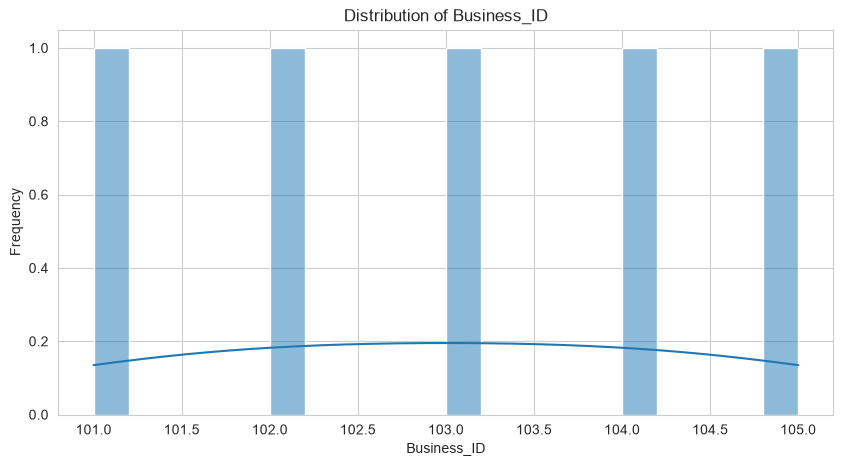

In [50]:
if len(numeric_columns) > 0:

    column = numeric_columns[0]

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df,
        x=column,
        bins=20,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

else:
    print("No numerical columns found!")

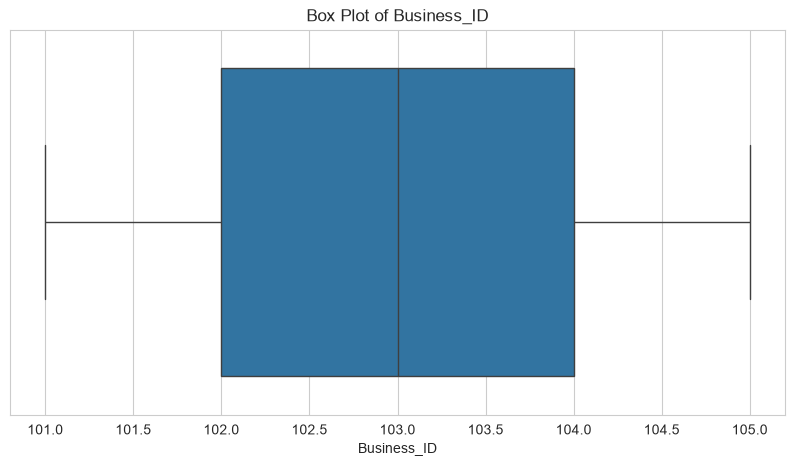

In [52]:
if len(numeric_columns) > 0:
    column = numeric_columns[0]

    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[column].dropna())

    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    plt.show()
else:
    print("No numerical columns found!")

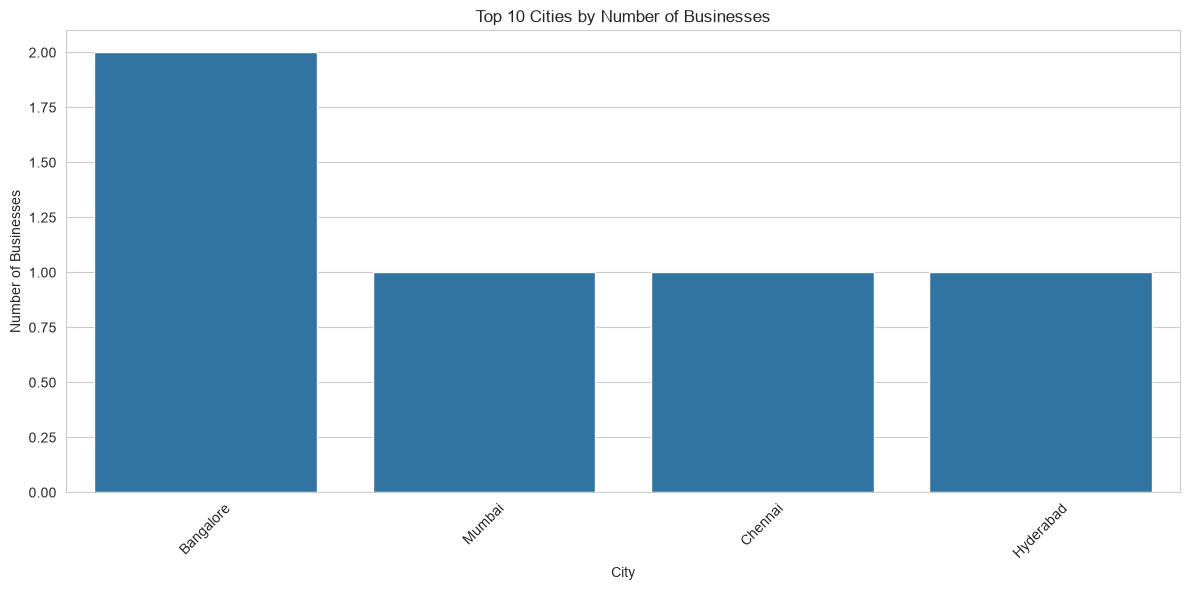

In [56]:
city_counts = df["City"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=city_counts.index, y=city_counts.values)

plt.title("Top 10 Cities by Number of Businesses")
plt.xlabel("City")
plt.ylabel("Number of Businesses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

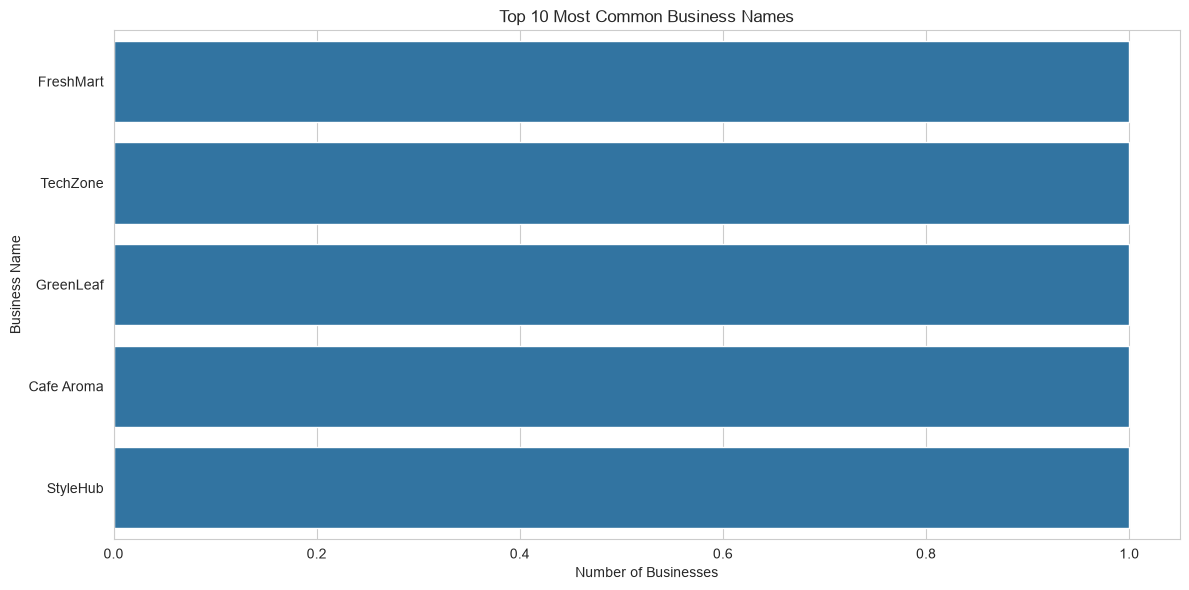

In [58]:
top_businesses = df["Business_Name"].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_businesses.values, y=top_businesses.index)

plt.title("Top 10 Most Common Business Names")
plt.xlabel("Number of Businesses")
plt.ylabel("Business Name")
plt.tight_layout()
plt.show()

In [60]:
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))

    correlation = numeric_df.corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numerical columns for a correlation heatmap.")

Not enough numerical columns for a correlation heatmap.


In [62]:
print("Numerical columns:")
print(numeric_df.columns.tolist())

print("\nNumber of numerical columns:")
print(numeric_df.shape[1])

Numerical columns:
['Business_ID']

Number of numerical columns:
1


In [64]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Business_ID    5 non-null      int64
 1   Business_Name  5 non-null      str  
 2   City           5 non-null      str  
dtypes: int64(1), str(2)
memory usage: 252.0 bytes


In [66]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Business_ID      0
Business_Name    0
City             0
dtype: int64


In [70]:
print(df.columns.tolist())

['Business_ID', 'Business_Name', 'City']


In [72]:
df.columns = df.columns.str.strip()

print("Cleaned column names:")
print(df.columns.tolist())

Cleaned column names:
['Business_ID', 'Business_Name', 'City']


In [74]:
print("Total duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Business IDs:",
    df["Business ID"].duplicated().sum()
)

Total duplicate rows: 0


KeyError: 'Business ID'

In [76]:
for col in df.columns:
    print(repr(col))
    

'Business_ID'
'Business_Name'
'City'


In [78]:
df.columns = (
    df.columns
    .str.strip()
    .str.replace("_", " ")
)

print(df.columns.tolist())

['Business ID', 'Business Name', 'City']


In [80]:
print("Total duplicate rows:", df.duplicated().sum())

business_id_col = [
    col for col in df.columns
    if "business" in col.lower() and "id" in col.lower()
]

print("Business ID column found:", business_id_col)

if business_id_col:
    print(
        "Duplicate Business IDs:",
        df[business_id_col[0]].duplicated().sum()
    )

Total duplicate rows: 0
Business ID column found: ['Business ID']
Duplicate Business IDs: 0


In [82]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (5, 3)

Column names:
['Business ID', 'Business Name', 'City']

First 5 rows:


,Business ID,Business Name,City
0,101,FreshMart,Bangalore
1,102,TechZone,Mumbai
2,103,GreenLeaf,Chennai
3,104,Cafe Aroma,Bangalore
4,105,StyleHub,Hyderabad


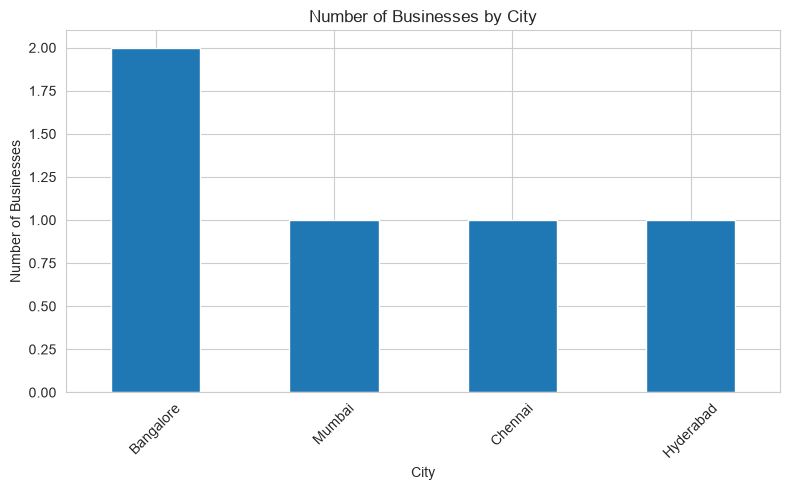

In [84]:
city_counts = df["City"].value_counts()

plt.figure(figsize=(8, 5))
city_counts.plot(kind="bar")

plt.title("Number of Businesses by City")
plt.xlabel("City")
plt.ylabel("Number of Businesses")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()